# Data preparation and exploration

Port of the root notebook `data_analysis.ipynb` to the new API. Two parts:

1. **Preparation.** The raw workbook `Data/data_important.xlsx` is filtered and renamed into the CSV files of `Data/` that the whole pipeline reads (`data.py`): balanced and imbalanced metabolites, enzymes, fluxes, the cellular needs $b = S\,v_\mathrm{measured}$ and the measurement errors. The notebook rebuilds every table **in memory** and compares it with the committed CSV. It never overwrites `Data/`: with `HK_RUN=1` the rebuilt tables are written to `<OUT>/data_rebuilt/` (copy them over `Data/` by hand if you really want to regenerate them).
2. **Exploration.** What the data look like: coverage (which metabolite is measured in which condition), ranges, flux and enzyme levels, measurement errors, consistency of the fluxes with the stoichiometry, and the PGI thermodynamic consistency of the data.

The glucose row of the old data had its labels shifted against its values (sheet `ExtracelularRead`); the rebuild takes it by label from the sheet `Extracelular` (header row `Sample ID`), which is also what the one-shot repair script `fix_glc_row.py` did. That script stays at the repo root as the documented repair of `Data/` (it keeps the backup of the old row); the check it performs (`--check`) is repeated below.

In [1]:
import os
import sys
import logging
import warnings

HERE = os.getcwd()
REPO = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
for path in (os.path.join(REPO, "notebooks"), os.path.join(REPO, "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import settings  # noqa: F401  (pins BLAS / OpenMP to one thread before numpy is loaded)
from paths import check_out_dir, resolve_out

OUT = resolve_out(os.environ.get("HK_OUT") or settings.RUN["out_dir"])   # default: out_dir of settings/run.csv; relative paths are relative to the repo root
RUN = os.environ.get("HK_RUN", "0") == "1"

try:
    check_out_dir(OUT)
    WRITABLE = True
except ValueError:
    WRITABLE = False

if RUN and not WRITABLE:
    raise ValueError("HK_RUN=1 refuses an output directory inside results/, results_v2/ or results_v3/: %s" % OUT)

warnings.filterwarnings("ignore")
logging.getLogger("pyomo").setLevel(logging.ERROR)
print("REPO     :", REPO)
print("OUT      :", OUT)
print("RUN      :", RUN, "(False = load the saved results of OUT; True = compute and save into OUT)")
print("WRITABLE :", WRITABLE, "(tables / figures / report are written to OUT only if True)")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from model.parameters import (BALANCED_KEYS, IMBALANCED_KEYS, LI_FLUX_KEYS, FREE_DRAIN_KEYS, FLUX_KEYS, ENZYME_KEYS,
                              LEGACY_ROW_ORDER)
from model.stoichiometry import build_stoichiometric_matrix, stoichiometric_table, load_keq
from data import load_data_frames, load_measurement_sigmas, available_conditions
from paths import DATA_DIR

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
DATA = DATA_DIR

REPO     : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733
OUT      : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results_v4/flux_model
RUN      : True (False = load the saved results of OUT; True = compute and save into OUT)
WRITABLE : True (tables / figures / report are written to OUT only if True)


## 1. Preparation from the workbook

Sheets used: `ProteinRead` (enzymes), `MetaboliteRead` (intracellular metabolites), `FluxesRead` (fluxes), `Extracelular` (external glucose), `MetQ` and `FluxQ` (measurement errors). Filters, as in the original notebook:

* the 8 glycolytic enzymes, conditions where any of them is missing are dropped;
* the 9 balanced metabolites (only 6 are measured: g6p, f6p, fbp, dhap, 3pg, pep; g3p, pgp, 2pg are unmeasured) and the cofactors ATP, ADP, NAD, NADH, Pi, pyruvate plus external glucose (the nucleotides AMP, GDP, GTP stay in the CSV but are not used by the model);
* the 9 fluxes of the pathway, missing values and `-` set to 0;
* only the conditions present in all four tables (22 conditions).

In [2]:
xlsx = os.path.join(DATA, "data_important.xlsx")
proteins = pd.read_excel(xlsx, sheet_name="ProteinRead", index_col=0)
metabolites = pd.read_excel(xlsx, sheet_name="MetaboliteRead", index_col=0)
fluxes = pd.read_excel(xlsx, sheet_name="FluxesRead", index_col=0)
external = pd.read_excel(xlsx, sheet_name="Extracelular", index_col=0)

enzyme_names = {"pgi": "Pgi", "pfkB": "PfkB", "fbaA": "FbaA", "tpiA": "TpiA", "gapA": "GapA", "pgk": "Pgk",
                "gpmA": "GpmA", "eno": "Eno"}
balanced_names = {"Phosphoenolpyruvate": "C_pep", "Dihydroxyacetone phosphate": "C_dhap", "3-Phosphoglycerate": "C_3pg",
                  "Fructose 6-phosphate": "C_f6p", "Fructose 1,6-diphosphate": "C_fbp", "Glucose 6-phosphate": "C_g6p"}
unmeasured = ["Glyceraldehyde 3-phosphate", "1,3-Bisphosphoglycerate", "2-Phosphoglycerate"]
imbalanced_names = {"ATP": "C_atp", "ADP": "C_adp", "NAD": "C_nad", "NADH": "C_nadh", "Inorganic phosphate": "C_pi",
                    "Pyruvate": "C_pyr", "AMP": "C_amp", "GDP": "C_gdp", "GTP": "C_gtp", "Glucose": "C_glc"}
flux_names = {"Glucose + PEP -> G6P + PYR": "v_pts", "G6P <-> F6P": "v_pgi", "F6P -> F1,6P": "v_pfkB",
              "F1,6P -> DHAP + G3P": "v_fbaA", "DHAP -> G3P": "v_tpiA", "G3P -> PGP": "v_gapA", "PGP -> 3PG": "v_pgk",
              "3PG <-> 2PG": "v_gpmA", "2PG <-> PEP": "v_eno"}

prot_f = proteins[proteins.index.isin(list(enzyme_names))]
bal_f = metabolites[metabolites.index.isin(list(balanced_names) + unmeasured)]
imb_f = pd.concat([metabolites[metabolites.index.isin([k for k in imbalanced_names if k != "Glucose"])],
                   external[external.index.isin(["Glucose"])]])
flux_f = fluxes[fluxes.index.isin(list(flux_names))].fillna(0).replace("-", 0)

prot_f = prot_f.loc[:, prot_f.notna().all(axis=0)]
conditions = bal_f.columns.intersection(imb_f.columns).intersection(flux_f.columns).intersection(prot_f.columns)
print("conditions kept: %d" % len(conditions), list(conditions))

rebuilt = {
    "balanced_metabolites": bal_f[conditions].loc[[k for k in bal_f.index if k in balanced_names]].rename(index=balanced_names),
    "imbalanced_metabolites": imb_f[conditions].rename(index=imbalanced_names),
    "important_proteins": prot_f[conditions].rename(index=enzyme_names),
    "important_fluxes": flux_f[conditions].rename(index=flux_names),
}

conditions kept: 22 ['KO02', 'KO03', 'KO04', 'KO05', 'KO07', 'KO08', 'KO10', 'KO11', 'KO12', 'KO13', 'KO14', 'KO15', 'KO16', 'KO17', 'KO18', 'KO19', 'KO20', 'KO21', 'KO22', 'KO23', 'KO24', 'RF03']


In [3]:
# cellular needs b = S v_measured (rows in the order of the stoichiometric table, named C_<met>)
S_alpha = stoichiometric_table(["C_" + m for m in LEGACY_ROW_ORDER])
needs = pd.DataFrame({c: S_alpha.to_numpy() @ rebuilt["important_fluxes"][c].to_numpy(dtype=float) for c in conditions},
                     index=["C_" + m for m in S_alpha.index])
rebuilt["cellular_needs"] = needs

# measurement errors
met_q = pd.read_excel(xlsx, sheet_name="MetQ", index_col=0)
flux_q = pd.read_excel(xlsx, sheet_name="FluxQ", index_col=0)
met_q = met_q[met_q.index.isin(list(balanced_names) + unmeasured)]
met_q.index = met_q.index.map(balanced_names)
met_q = met_q.drop(columns=["Ave", "CV"])
flux_q = flux_q[flux_q.index.isin(list(flux_names))]
flux_q.index = flux_q.index.map(flux_names)
rebuilt["balanced_metabolites_Q"] = met_q
rebuilt["important_fluxes_Q"] = flux_q[["STD"]]

### Comparison with the committed CSV files

For every table: rows and columns that differ and the largest absolute difference over the common cells. A table is reproduced when both sets are empty and the difference is 0. (Rows of the committed `balanced_metabolites_Q.csv` for unmeasured metabolites have no value and are compared as NaN.)

In [4]:
rows = []
for name, new in rebuilt.items():
    old = pd.read_csv(os.path.join(DATA, name + ".csv"), index_col=0)
    common_r = [r for r in old.index if r in new.index]
    common_c = [c for c in old.columns if c in new.columns]
    diff = new.loc[common_r, common_c].astype(float).to_numpy() - old.loc[common_r, common_c].astype(float).to_numpy()
    rows.append({"table": name, "shape_rebuilt": new.shape, "shape_csv": old.shape,
                 "rows_only_csv": ", ".join(sorted(set(old.index) - set(new.index))),
                 "rows_only_rebuilt": ", ".join(sorted(set(new.index) - set(old.index))),
                 "max_abs_diff": float(np.nanmax(np.abs(diff))) if diff.size else np.nan})

comparison = pd.DataFrame(rows).set_index("table")
comparison

,shape_rebuilt,shape_csv,rows_only_csv,rows_only_rebuilt,max_abs_diff
table,,,,,
balanced_metabolites,"(6, 22)","(6, 22)",,,0.000000e+00
imbalanced_metabolites,"(9, 22)","(9, 22)",,,0.000000e+00
important_proteins,"(8, 22)","(8, 22)",,,0.000000e+00
important_fluxes,"(9, 22)","(9, 22)",,,0.000000e+00
cellular_needs,"(9, 22)","(9, 22)",,,2.220446e-16
balanced_metabolites_Q,"(6, 1)","(6, 1)",,,0.000000e+00
important_fluxes_Q,"(9, 1)","(9, 1)",,,0.000000e+00


In [5]:
# the check of fix_glc_row.py --check: glucose by label from the sheet Extracelular against the committed CSV
raw = pd.read_excel(xlsx, sheet_name="Extracelular", header=None)
labels = raw.iloc[0].tolist()
glc_by_label = {lab: float(raw.iloc[raw.iloc[:, 0].tolist().index("Glucose"), j])
                for j, lab in enumerate(labels) if isinstance(lab, str) and lab != "Sample ID"}
csv_glc = pd.read_csv(os.path.join(DATA, "imbalanced_metabolites.csv"), index_col=0).loc["C_glc"].astype(float)
print("max |csv C_glc - sheet Extracelular by label| = %.3g" % max(abs(csv_glc[c] - glc_by_label[c]) for c in csv_glc.index))

max |csv C_glc - sheet Extracelular by label| = 0


In [6]:
if RUN:
    target = os.path.join(OUT, "data_rebuilt")
    os.makedirs(target, exist_ok=True)
    for name, table in rebuilt.items():
        table.to_csv(os.path.join(target, name + ".csv"))
    print("rebuilt tables written to", target, "(Data/ is never written by this notebook)")
else:
    print("RUN is False: nothing written (HK_RUN=1 writes the rebuilt tables to <OUT>/data_rebuilt/)")

rebuilt tables written to /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results_v4/flux_model/data_rebuilt (Data/ is never written by this notebook)


## 2. Exploration

The files below are read through the same functions the pipeline uses (`data.load_data_frames`, `data.load_measurement_sigmas`).

In [7]:
bal_df, imb_df, prot_df, flux_df, needs_df = load_data_frames()
sigma_flux, sigma_met = load_measurement_sigmas()
conds = available_conditions()

summary = pd.DataFrame({
    "table": ["balanced metabolites", "imbalanced metabolites", "enzymes", "fluxes", "cellular needs b"],
    "rows": [bal_df.shape[0], imb_df.shape[0], prot_df.shape[0], flux_df.shape[0], needs_df.shape[0]],
    "conditions": [bal_df.shape[1], imb_df.shape[1], prot_df.shape[1], flux_df.shape[1], needs_df.shape[1]],
    "missing cells": [int(bal_df.isna().sum().sum()), int(imb_df.isna().sum().sum()), int(prot_df.isna().sum().sum()),
                      int(flux_df.isna().sum().sum()), int(needs_df.isna().sum().sum())],
}).set_index("table")
print("%d conditions: %s" % (len(conds), conds))
summary

22 conditions: ['KO02', 'KO03', 'KO04', 'KO05', 'KO07', 'KO08', 'KO10', 'KO11', 'KO12', 'KO13', 'KO14', 'KO15', 'KO16', 'KO17', 'KO18', 'KO19', 'KO20', 'KO21', 'KO22', 'KO23', 'KO24', 'RF03']


,rows,conditions,missing cells
table,,,
balanced metabolites,6,22,29
imbalanced metabolites,9,22,26
enzymes,8,22,0
fluxes,9,22,0
cellular needs b,9,22,0


### Coverage of the balanced metabolites

Every condition measures only part of the balanced metabolites, and g3p, pgp and 2pg are never measured (they are free variables of the fit, pinned only by the steady-state constraint). The map shows which cell enters the objective.

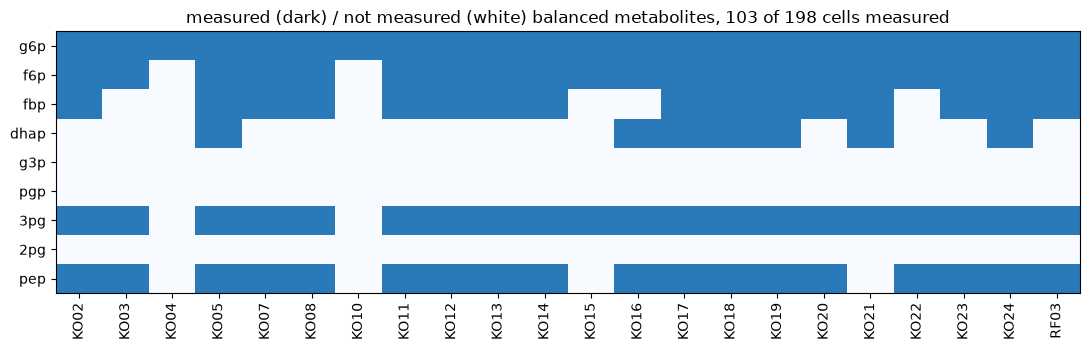

In [8]:
cover = pd.DataFrame(index=BALANCED_KEYS, columns=conds, dtype=float)
for k in BALANCED_KEYS:
    for c in conds:
        cover.loc[k, c] = float(k in bal_df.index and pd.notna(bal_df.loc[k, c]))

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.imshow(cover.to_numpy(dtype=float), aspect="auto", cmap="Blues", vmin=0, vmax=1.4)
ax.set_xticks(range(len(conds)))
ax.set_xticklabels(conds, rotation=90)
ax.set_yticks(range(len(BALANCED_KEYS)))
ax.set_yticklabels([k[2:] for k in BALANCED_KEYS])
ax.set_title("measured (dark) / not measured (white) balanced metabolites, %d of %d cells measured" % (
    int(cover.to_numpy().sum()), cover.size))
fig.tight_layout()
plt.show()

### Concentrations and fluxes across conditions

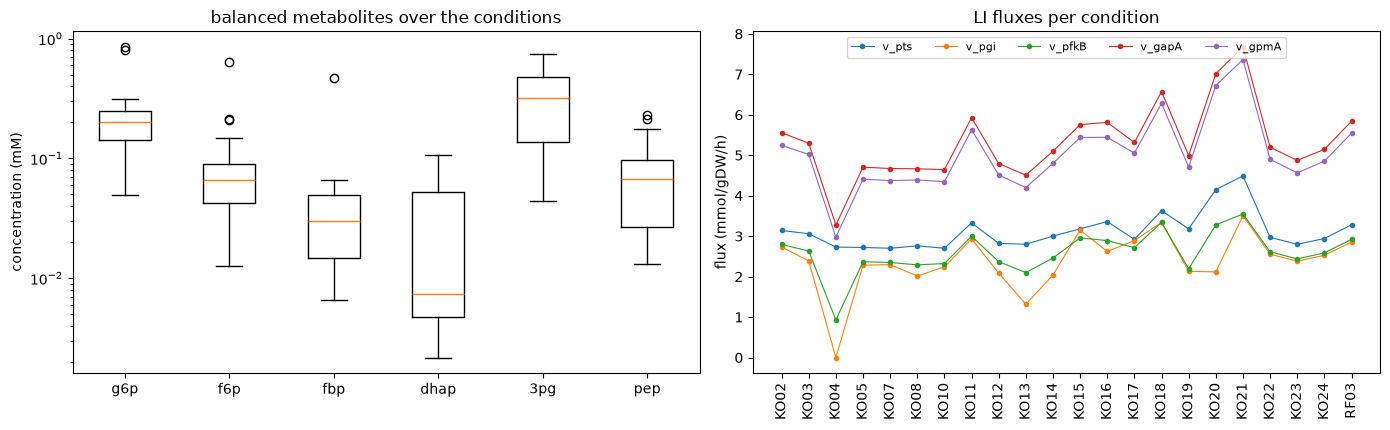

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
ax_met, ax_flux = axes

# metabolites: one box per metabolite over the conditions (log scale)
met_rows = [k for k in BALANCED_KEYS if k in bal_df.index]
ax_met.boxplot([bal_df.loc[k].astype(float).dropna().to_numpy() for k in met_rows], tick_labels=[k[2:] for k in met_rows])
ax_met.set_yscale("log")
ax_met.set_ylabel("concentration (mM)")
ax_met.set_title("balanced metabolites over the conditions")

# fluxes of the 5 linearly independent set, per condition
for k in LI_FLUX_KEYS:
    ax_flux.plot(range(len(conds)), flux_df.loc[k, conds].astype(float), "o-", ms=3, lw=0.8, label=k)

ax_flux.set_xticks(range(len(conds)))
ax_flux.set_xticklabels(conds, rotation=90)
ax_flux.set_ylabel("flux (mmol/gDW/h)")
ax_flux.legend(ncol=5, fontsize=8, loc="upper center")
ax_flux.set_title("LI fluxes per condition")

fig.tight_layout()
plt.show()

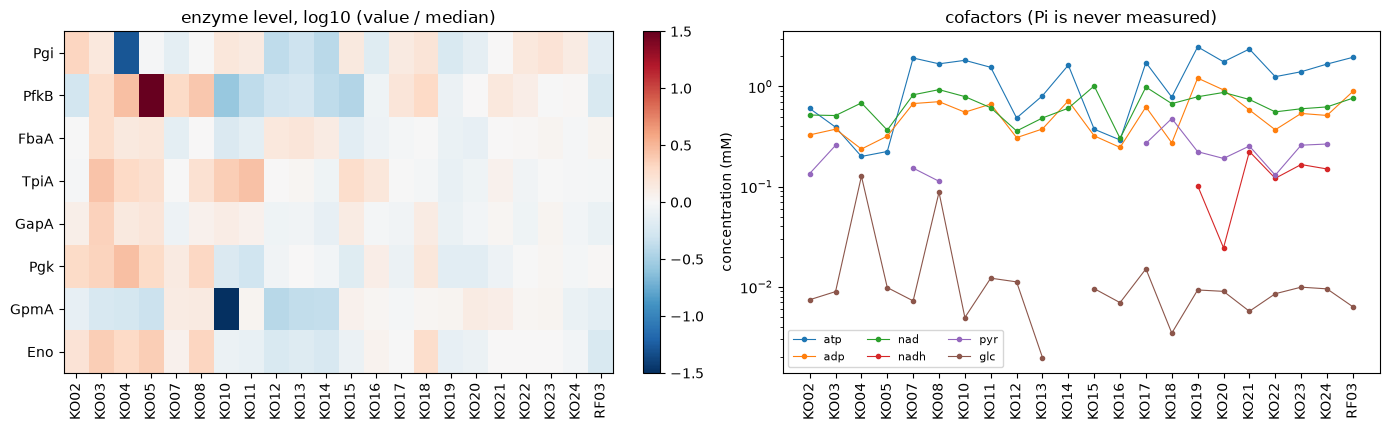

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
ax_enz, ax_cof = axes

# enzymes: log10 relative to the median over the conditions
rel = np.log10(prot_df.astype(float).div(prot_df.astype(float).median(axis=1), axis=0))
im = ax_enz.imshow(rel.to_numpy(), aspect="auto", cmap="RdBu_r", vmin=-1.5, vmax=1.5)
ax_enz.set_xticks(range(len(conds)))
ax_enz.set_xticklabels(conds, rotation=90)
ax_enz.set_yticks(range(len(rel.index)))
ax_enz.set_yticklabels(rel.index)
ax_enz.set_title("enzyme level, log10 (value / median)")
fig.colorbar(im, ax=ax_enz, fraction=0.03)

# cofactors that enter the model, log scale
for k in IMBALANCED_KEYS:
    if k in imb_df.index:
        vals = imb_df.loc[k, conds].astype(float)
        ax_cof.plot(range(len(conds)), vals.where(vals > 0), "o-", ms=3, lw=0.8, label=k[2:])

ax_cof.set_yscale("log")
ax_cof.set_xticks(range(len(conds)))
ax_cof.set_xticklabels(conds, rotation=90)
ax_cof.set_ylabel("concentration (mM)")
ax_cof.legend(ncol=3, fontsize=8)
ax_cof.set_title("cofactors (Pi is never measured)")

fig.tight_layout()
plt.show()

### Measurement errors

The weighted objective divides every residual by its $\sigma$ (`Data/balanced_metabolites_Q.csv`, `Data/important_fluxes_Q.csv`): one $\sigma$ per output, the same in all conditions. The relative error $\sigma / \bar y$ shows which outputs the fit trusts most.

In [11]:
sig_rows = []
for k, s in sigma_met.items():
    if s is not None and k in bal_df.index:
        sig_rows.append({"output": k, "sigma": s, "mean_value": float(bal_df.loc[k].astype(float).mean())})

for k in LI_FLUX_KEYS:
    sig_rows.append({"output": k, "sigma": sigma_flux[k], "mean_value": float(flux_df.loc[k].astype(float).mean())})

sig_table = pd.DataFrame(sig_rows).set_index("output")
sig_table["relative_error"] = sig_table["sigma"] / sig_table["mean_value"]
sig_table

,sigma,mean_value,relative_error
output,,,
C_pep,0.047200,0.082611,0.571352
C_3pg,0.190000,0.337900,0.562297
C_f6p,0.012100,0.103820,0.116548
C_g6p,0.042300,0.246545,0.171571
C_fbp,0.007440,0.058637,0.126883
v_pts,0.312143,3.120909,0.100017
v_pgi,0.626764,2.381468,0.263184
v_pfkB,0.406177,2.594836,0.156533
v_gapA,0.735681,5.333282,0.137942


### Consistency checks

1. The cellular needs are $b = S\,v_\mathrm{measured}$ by construction; they are the data of the free drains (and their bounds).
2. The 9 fluxes contain 5 independent values: pfkB = fbaA = tpiA, gapA = pgk, gpmA = eno in every condition (the zero-drain balances of fbp, dhap, pgp, 2pg).
3. PGI thermodynamics: a positive net flux needs $\gamma = 1 - (f6p/g6p)/K_{eq} > 0$. Conditions where the measured ratio exceeds $K_{eq}$ with a positive measured $v_\mathrm{pgi}$ violate it, which puts a floor under the objective of any model of this form.

In [12]:
S = build_stoichiometric_matrix()
b_check = pd.DataFrame(S @ flux_df.loc[FLUX_KEYS, conds].to_numpy(dtype=float), index=["C_" + k[2:] for k in BALANCED_KEYS], columns=conds)
print("max |b - S v| over the committed cellular_needs.csv: %.2e" % float(np.abs(
    b_check.to_numpy() - needs_df.loc[b_check.index, conds].to_numpy(dtype=float)).max()))

dups = {"pfkB = fbaA = tpiA": (("v_pfkB", "v_fbaA"), ("v_pfkB", "v_tpiA")),
        "gapA = pgk": (("v_gapA", "v_pgk"),), "gpmA = eno": (("v_gpmA", "v_eno"),)}
for name, pairs in dups.items():
    print("%-22s max |difference|: %.2e" % (name, max(float(np.abs(flux_df.loc[a] - flux_df.loc[b]).max()) for a, b in pairs)))

keq = load_keq()
ratio = (bal_df.loc["C_f6p"].astype(float) / bal_df.loc["C_g6p"].astype(float)).dropna()
viol = pd.DataFrame({"f6p/g6p": ratio, "Keq_pgi": keq["pgi"], "v_pgi": flux_df.loc["v_pgi", ratio.index].astype(float)})
viol = viol[(viol["f6p/g6p"] > viol["Keq_pgi"]) & (viol["v_pgi"] > 0)]
print("conditions where the data violate the PGI thermodynamics: %d" % len(viol))
viol

max |b - S v| over the committed cellular_needs.csv: 0.00e+00
pfkB = fbaA = tpiA     max |difference|: 0.00e+00
gapA = pgk             max |difference|: 0.00e+00
gpmA = eno             max |difference|: 0.00e+00
conditions where the data violate the PGI thermodynamics: 6


,f6p/g6p,Keq_pgi,v_pgi
KO02,0.439189,0.381019,2.7318
KO18,0.785891,0.381019,3.3396
KO19,0.515571,0.381019,2.1306
KO20,0.715254,0.381019,2.1165
KO21,0.486111,0.381019,3.5022
KO22,0.665179,0.381019,2.5542
